# Simulated Annealing Schedules

Michael Hahsler

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Cooling Schedules

### Exponential Schedule

See [1].

In [2]:
def temperature_exponential(time, initial_temperature, alpha):
    return initial_temperature * alpha**time

### Linear Schedule

See [1].

In [3]:
def temperature_linear(time, initial_temperature, eta):
    return initial_temperature - eta * time

### Fast Simulated Annealing

See [3].

In [4]:
def temperature_fast(time, initial_temperature):
    return initial_temperature / (1 + time)

### Logarithmic (Classic) Cooling

If $T_0$ is greater than or equal to the largest energy barrier in the problem, this schedule is guaranteed to find the global optimum in the limit of infinite time [2]. The schedule is defined for $t > 0$.

In [5]:
def temperature_logarithmic(time, initial_temperature):
    return initial_temperature / np.log1p(time)

## Comparison

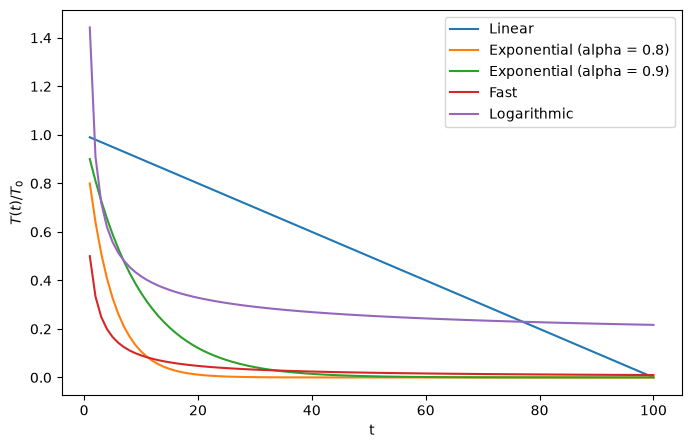

In [6]:
time = np.arange(1, 101)
initial_temperature = 1

schedules = {
    "Linear": temperature_linear(time, initial_temperature, eta=0.01),
    "Exponential (alpha = 0.8)": temperature_exponential(
        time, initial_temperature, alpha=0.8
    ),
    "Exponential (alpha = 0.9)": temperature_exponential(
        time, initial_temperature, alpha=0.9
    ),
    "Fast": temperature_fast(time, initial_temperature),
    "Logarithmic": temperature_logarithmic(time, initial_temperature),
}

plt.figure(figsize=(8, 5))
for name, temperature in schedules.items():
    plt.plot(time, temperature / initial_temperature, label=name)

plt.xlabel("t")
plt.ylabel(r"$T(t) / T_0$")
plt.legend()
plt.show()

In [7]:
def cooling_technique(initial_temperature=1, alpha=0.8, eta=0.01):
    time = np.arange(1, 101)

    schedules = {
        f"Linear (eta = {eta})": temperature_linear(time, initial_temperature, eta=eta),
        f"Exponential (alpha = {alpha})": temperature_exponential(
            time, initial_temperature, alpha=alpha
        ),
        # "Fast": temperature_fast(time, initial_temperature),
        # "Logarithmic": temperature_logarithmic(time, initial_temperature),
    }

    plt.figure(figsize=(8, 5))
    for name, temperature in schedules.items():
        plt.plot(time, temperature / initial_temperature, label=name)

    plt.xlabel("t")
    plt.ylabel(r"$T(t) / T_0$")
    plt.legend()
    plt.show()

## Evaluate

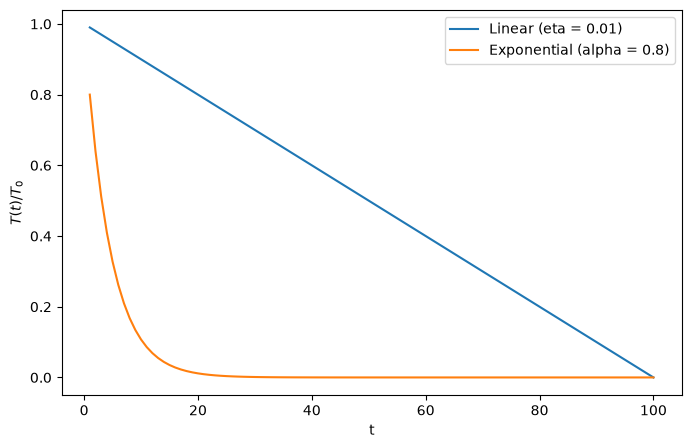

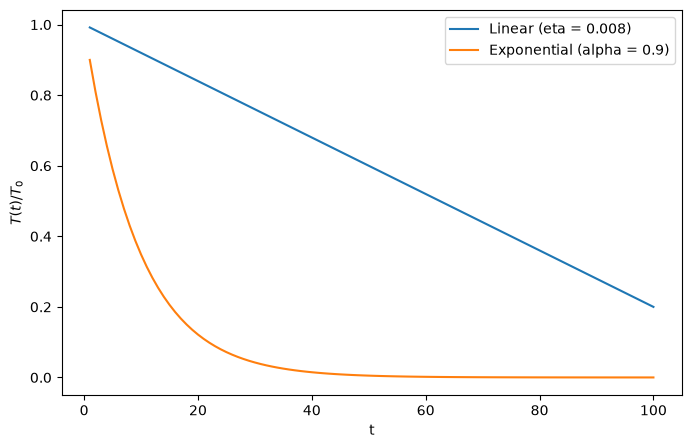

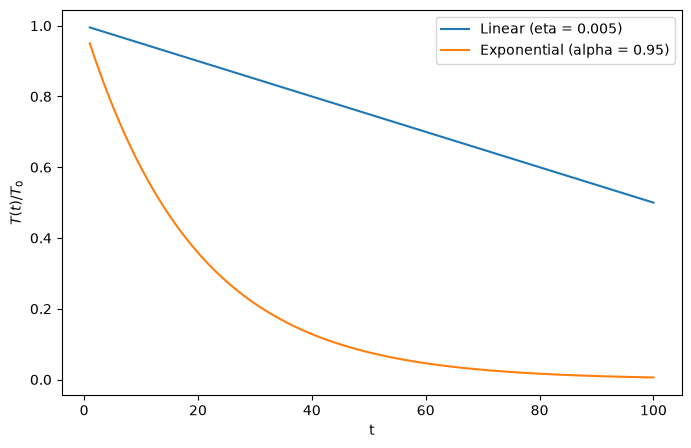

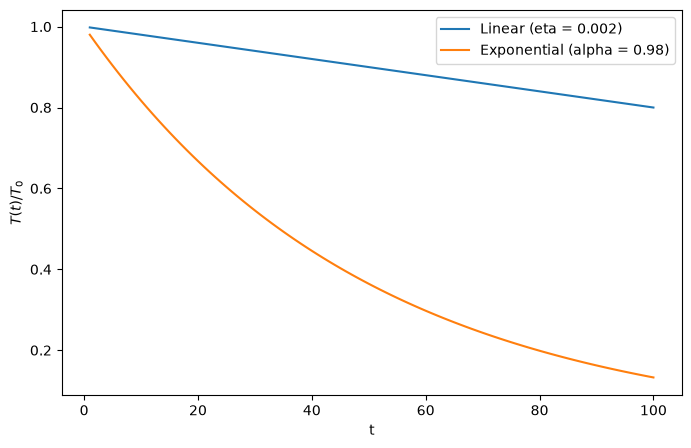

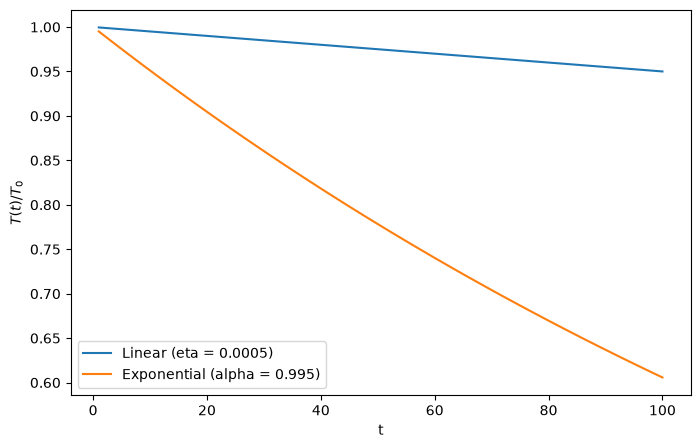

In [8]:
test_parameters = [
    {"initial_temperature": 1.0, "alpha": 0.80,  "eta": 0.0100},
    {"initial_temperature": 1.0, "alpha": 0.90,  "eta": 0.0080},
    {"initial_temperature": 1.0, "alpha": 0.95,  "eta": 0.0050},
    {"initial_temperature": 1.0, "alpha": 0.98,  "eta": 0.0020},
    {"initial_temperature": 1.0, "alpha": 0.995, "eta": 0.0005},
]

for parameters in test_parameters:
    cooling_technique(**parameters)

Nhận xét:
* __Linear__: khả năng giữ nhiệt phụ thuộc vào eta; eta càng nhỏ càng giữ nhiệt lâu.
* __Exponential__: phụ thuộc mạnh vào alpha; alpha càng gần 1 càng giữ nhiệt lâu.
* __Fast__: giảm rất nhanh lúc đầu vì $T(t)=T_0/(1+t)$.
* __Logarithmic__: thường giảm chậm về lâu dài, nên thường giữ nhiệt tốt hơn Fast và exponential với alpha nhỏ.
Không thể khẳng định một schedule luôn giữ nhiệt lâu nhất mà không xét tham số. Chẳng hạn exponential với alpha=0.995 có thể giữ nhiệt cao hơn logarithmic trong 100 bước.

## SA

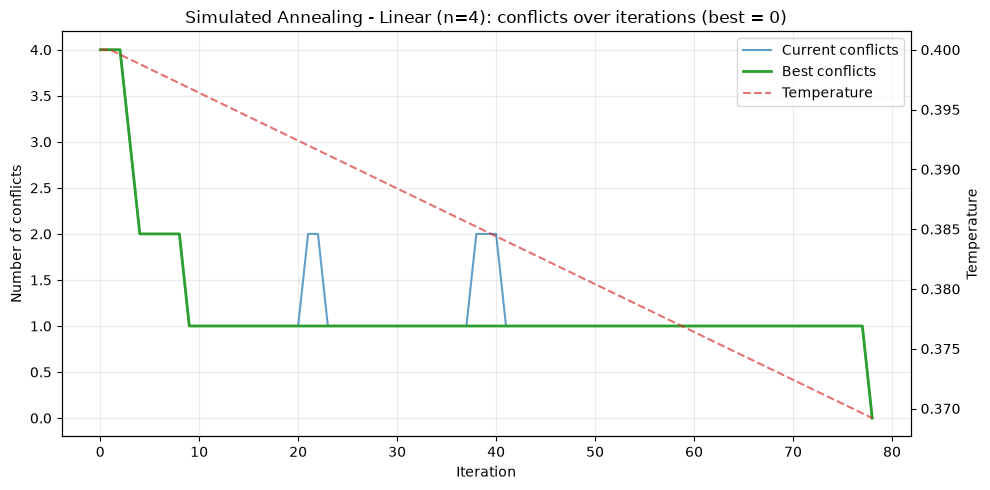

{'experiment_id': 'ex5_task5_SA_linear_20261013_142539_041137',
 'run_id': 'Simulated_Annealing_-_Linear_n4_run001_20261013_142539_041971',
 'run_number': 1,
 'board_size': 4,
 'best_board': [1, 3, 0, 2],
 'best_conflicts': 0,
 'iterations': 78,
 'history': '79 records',
 'runtime_ms': 0.690176006173715,
 'seed': 1234,
 'success': True}

History CSV: logs/ex5_task5_SA_linear_20261013_142539_041137/histories/Simulated_Annealing_-_Linear_n4/Simulated_Annealing_-_Linear_n4_run001_20261013_142539_041971.csv
Runs CSV: logs/ex5_task5_SA_linear_20261013_142539_041137/runs.csv
Summary CSV: logs/ex5_task5_SA_linear_20261013_142539_041137/summary.csv
Biểu đồ run: img/task_5_SA/ex5_task5_SA_linear_20261013_142539_041137/runs/Simulated_Annealing_-_Linear_n4_run001_20261013_142539_041971.png


In [9]:
from simulated_annealing import simulated_annealing
from helper import random_board, conflicts, show_board, create_experiment_id, save_log_result, summarize_experiment
import numpy as np
from pathlib import Path

single_experiment_id = create_experiment_id("ex5_task5_SA_linear")

single_n4_result = simulated_annealing(n=4, mode=0)
single_n4_log = save_log_result(
    single_n4_result,
    algorithm="Simulated Annealing - Linear",
    experiment_id=single_experiment_id,
    run_number=1,
    plot_run=True,
    show_plot=True,
)

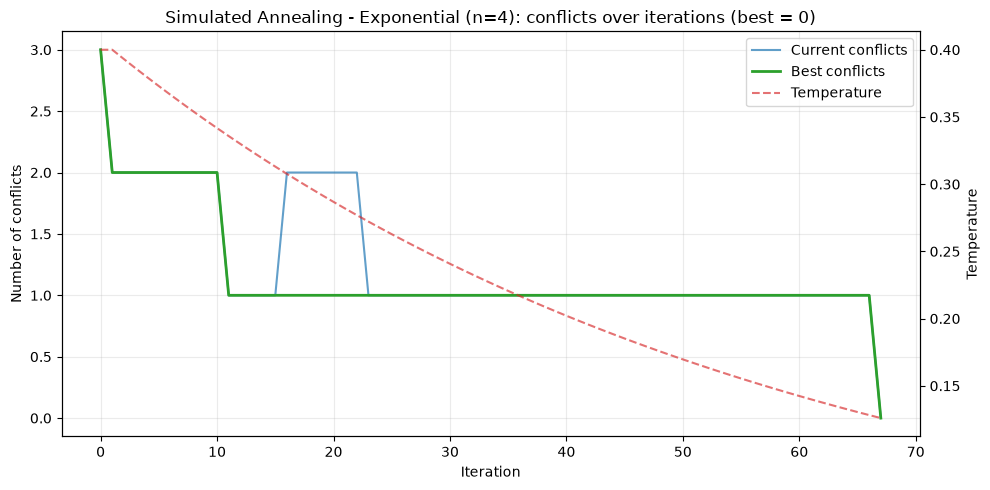

{'experiment_id': 'ex5_task5_SA_exp_20261013_142539_421488',
 'run_id': 'Simulated_Annealing_-_Exponential_n4_run001_20261013_142539_422728',
 'run_number': 1,
 'board_size': 4,
 'best_board': [1, 3, 0, 2],
 'best_conflicts': 0,
 'iterations': 67,
 'history': '68 records',
 'runtime_ms': 1.027280988637358,
 'seed': 1234,
 'success': True}

History CSV: logs/ex5_task5_SA_exp_20261013_142539_421488/histories/Simulated_Annealing_-_Exponential_n4/Simulated_Annealing_-_Exponential_n4_run001_20261013_142539_422728.csv
Runs CSV: logs/ex5_task5_SA_exp_20261013_142539_421488/runs.csv
Summary CSV: logs/ex5_task5_SA_exp_20261013_142539_421488/summary.csv
Biểu đồ run: img/task_5_SA/ex5_task5_SA_exp_20261013_142539_421488/runs/Simulated_Annealing_-_Exponential_n4_run001_20261013_142539_422728.png


In [10]:
from simulated_annealing import simulated_annealing
import numpy as np
from pathlib import Path

single_experiment_id = create_experiment_id("ex5_task5_SA_exp")

single_n4_result = simulated_annealing(n=4, mode=1)
single_n4_log = save_log_result(
    single_n4_result,
    algorithm="Simulated Annealing - Exponential",
    experiment_id=single_experiment_id,
    run_number=1,
    plot_run=True,
    show_plot=True,
)

## Review

* __Về mặt thời gian:__ Exponential Temperature cho ra được thời gian chạy nhanh hơn, khi chỉ tốn 68 giây để chạy so với 79 giây của Linear Temperature.

* __Về mặt chất lượng:__ Ở kích thước bảng n = 4, cả hai chiến lược đều đạt đến điểm conflicts tốt nhất = 0

## Literature

1. Kirkpatrick, S., Gelatt, C. D. Jr., and Vecchi, M. P. (1983). Optimization by simulated annealing. *Science*, 220, 671–680.
2. Hajek, B. (1988). Cooling schedules for optimal annealing. *Mathematics of Operations Research*, 13, 311–329.
3. Szu, H., and Hartley, R. (1987). Fast simulated annealing. *Physics Letters A*, 122(3–4), 157–162. [doi:10.1016/0375-9601(87)90796-1](https://doi.org/10.1016/0375-9601(87)90796-1)